# **Regresión Lineal**

El *análisis de la regresión* es un proceso estadístico para estimar las relaciones entre variables. Se puede implementar para estudiar la relación entre una variable dependiente (o variable respuesta) $y$ y una o más variables independientes (variables regresoras o predictoras) $x_1,x_2,...,x_n$ a través de una ecuación lineal.

En este rubro, se distinguen dos modalidades:

1) Regresión Lineal Simple:
 * Cuando se emplean únicamente dos variables: $x$, $y$

2) Regresión Lineal Multiple:
 * Cuando se tienen más de dos variables: $x_1,x_2,...,x_n,y$

La ecuación de regresión lineal es:

$$ \widehat{y}  = \theta_0 + \theta_1 x_1 + \theta_2 x_2 + ... + \theta_n x_n + \epsilon$$

donde:
* $\widehat{y}$: variable dependiente o respuesta.
* $n$: número de variables predictoras.
* $x_i$: *i-ésima* variable independiente o predictora.
* $\theta_j$: coeficientes de regresión ($\theta_0$ corresponde al intercepto y $\theta_1, \theta_2,...,\theta_n$ corresponden a los pesos asociados a las variables predictoras).
* $\epsilon$: error.

# Regresión lineal simple: Índice de masa corporal

Utilizaremos un *dataframe* de datos corporales para predecir el peso de una persona dado su índice de masa corporal.

Para ello, seguiremos la siguiente metodología:

* Análisis exploratorio de las variables elegidas para el modelo.
* Obtención de la ecuación de regresión
* Predicción de datos

#**Cargar librerías**

In [1]:
import pandas as pd
import numpy as np
%pip install seaborn
import seaborn as sns
import matplotlib.pyplot as plt

Cargar archivo BodyData.csv

In [2]:
df = pd.read_csv('student_exam_scores.csv', encoding='latin-1')
df

,student_id,hours_studied,sleep_hours,attendance_percent,previous_scores,exam_score
0,S001,8.0,8.8,72.1,45,30.2
1,S002,1.3,8.6,60.7,55,25.0
2,S003,4.0,8.2,73.7,86,35.8
3,S004,3.5,4.8,95.1,66,34.0
4,S005,9.1,6.4,89.8,71,40.3
...,...,...,...,...,...,...
195,S196,10.5,5.4,94.0,87,42.7
196,S197,7.1,6.1,85.1,92,40.4
197,S198,1.6,6.9,63.8,76,28.2
198,S199,12.0,7.3,50.5,58,42.0


Información general del conjunto de datos

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   student_id          200 non-null    str    
 1   hours_studied       200 non-null    float64
 2   sleep_hours         200 non-null    float64
 3   attendance_percent  200 non-null    float64
 4   previous_scores     200 non-null    int64  
 5   exam_score          200 non-null    float64
dtypes: float64(4), int64(1), str(1)
memory usage: 8.7 KB


## Análisis rápido

Columnas del df

In [4]:
df.columns

Index(['student_id', 'hours_studied', 'sleep_hours', 'attendance_percent',
       'previous_scores', 'exam_score'],
      dtype='str')

Descripción estadística

In [5]:
df.describe()

,hours_studied,sleep_hours,attendance_percent,previous_scores,exam_score
count,200.000000,200.000000,200.000000,200.000000,200.000000
mean,6.325500,6.622000,74.830000,66.800000,33.955000
std,3.227317,1.497138,14.249905,15.663869,6.789548
min,1.000000,4.000000,50.300000,40.000000,17.100000
25%,3.500000,5.300000,62.200000,54.000000,29.500000
50%,6.150000,6.700000,75.250000,67.500000,34.050000
75%,9.000000,8.025000,87.425000,80.000000,38.750000
max,12.000000,9.000000,100.000000,95.000000,51.300000


## Revisamos si existen valores vacíos o duplicados

<Axes: >

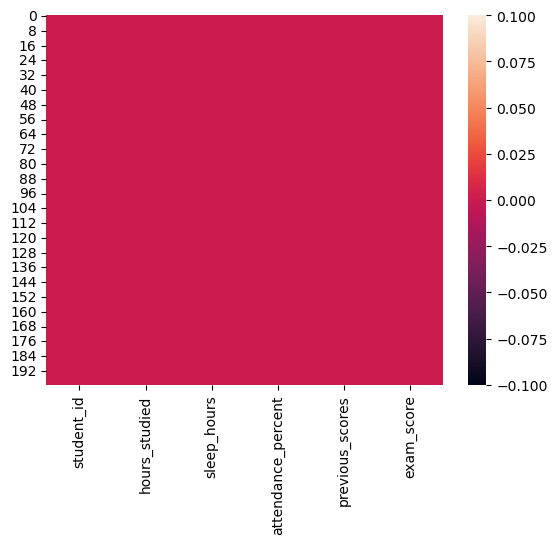

In [6]:
#Creamos un mapa de calor para identificar visualmente los atributos que tienen registros vacíos
sns.heatmap(df.isnull())

In [7]:
df.isnull().sum(axis=0)

student_id            0
hours_studied         0
sleep_hours           0
attendance_percent    0
previous_scores       0
exam_score            0
dtype: int64

In [8]:
# Revisar si existen duplicados


## Exportar csv

In [9]:
df.to_csv("student_exam_scores.csv",index=False)

## Análisis de correlación

In [10]:
df.corr()

<class 'ValueError'>: could not convert string to float: 'S001'

Mapa de calor para la correlación

In [11]:
#Correlación con la variable objetivo
corr_target= df.corrwith(df["exam_score"])
corr_target = corr_target.sort_values(ascending=False)
corr_target

<class 'ValueError'>: could not convert string to float: 'S001'

In [12]:
weight_corr = pd.DataFrame(df.corrwith(df["WEIGHT"]), columns=['Correlación'])
weight_corr

,Correlación
AGE,0.006136
GENDER (1=M),0.201537
PULSE,0.081605
SYSTOLIC,0.176407
DIASTOLIC,0.248287
HDL,-0.316812
LDL,0.086532
WHITE,0.245415
RED,0.196897
PLATE,0.008852


<Axes: >

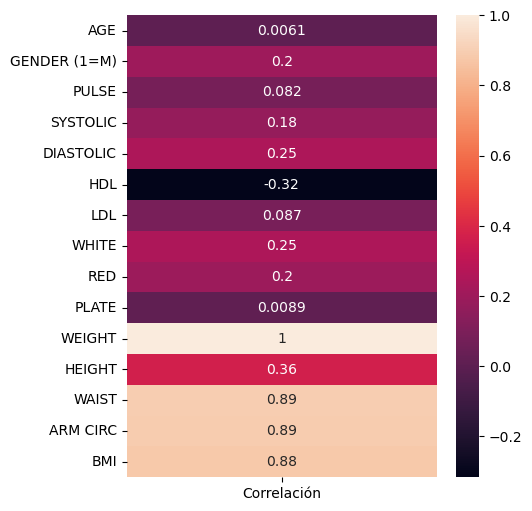

In [13]:
plt.figure(figsize=(5, 6))
sns.heatmap(weight_corr, annot=True)

<Axes: >

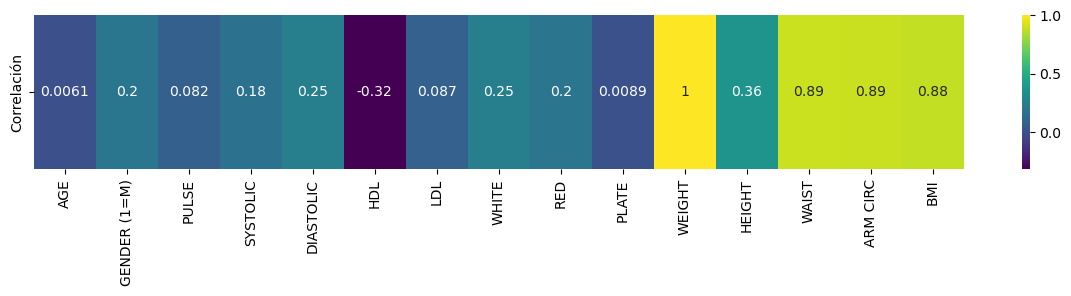

In [14]:
plt.figure(figsize=(15, 2))
sns.heatmap(weight_corr.T, annot=True, cmap='viridis')

# **Regresión lineal simple**

##Separación de conjunto en atributos y objetivo

Debemos identificar a nuestra variable independiente y a nuestra variable dependiente (variable objetivo).

In [14]:
X = df.drop(columns='exam_score')
y = df['exam_score']
X

,student_id,hours_studied,sleep_hours,attendance_percent,previous_scores
0,S001,8.0,8.8,72.1,45
1,S002,1.3,8.6,60.7,55
2,S003,4.0,8.2,73.7,86
3,S004,3.5,4.8,95.1,66
4,S005,9.1,6.4,89.8,71
...,...,...,...,...,...
195,S196,10.5,5.4,94.0,87
196,S197,7.1,6.1,85.1,92
197,S198,1.6,6.9,63.8,76
198,S199,12.0,7.3,50.5,58


In [15]:
y

0      30.2
1      25.0
2      35.8
3      34.0
4      40.3
       ... 
195    42.7
196    40.4
197    28.2
198    42.0
199    37.8
Name: exam_score, Length: 200, dtype: float64

Después, separamos nuestro conjunto de datos en el conjunto de prueba y el conjunto de entrenamiento.

Usaremos el 70% de los datos para entrenar a nuestro algoritmo y el 30% para probarlo.

In [29]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=0)
y_train

131    28.8
96     36.9
181    36.1
19     17.1
153    33.4
       ... 
67     32.2
192    28.8
117    31.3
47     31.1
172    31.0
Name: exam_score, Length: 140, dtype: float64

## Cálculo de los coeficientes de la ecuación de regresión lineal

Se utiliza el paquete *LinearRegression* para el cálculo de los coeficientes.

In [30]:
from sklearn.linear_model import LinearRegression
LR = LinearRegression()

In [31]:
LR.fit(X_train,y_train)

<class 'ValueError'>: could not convert string to float: 'S132'

In [24]:
LR.score(X_train, y_train)

<class 'AttributeError'>: 'LinearRegression' object has no attribute 'coef_'

In [23]:
pred = LR.predict(X_test)
pred

array([110.78394089,  94.35214738,  77.02407423, 121.24053675,
        85.6881108 , 113.47277982,  94.94966714, 106.30254266,
        83.29803175,  80.01167305,  96.44346655,  80.90795269,
        77.02407423,  91.06578868,  86.58439045,  73.14019576,
        79.41415328, 109.88766124,  75.8290347 ,  83.89555151,
       103.01618396,  79.71291317, 100.92486478,  92.85834797,
        81.80423234, 103.01618396,  65.07367895,  88.67570962,
        84.19431139,  81.80423234,  88.67570962,  97.04098632,
        81.20671257,  77.92035387,  90.7670288 ,  94.0533875 ,
        67.46375801,  83.59679163,  70.75011671, 116.75913853,
        95.24842703, 133.7884518 ,  75.8290347 , 114.36905947,
        76.12779458,  65.37243883])

Creamos una tabla para comparar los valores reales y los que el modelo predice.

In [25]:
comparacion = X_test.copy()
comparacion = comparacion.join(y_test)
comparacion['Predicción'] = pred
comparacion

<class 'NameError'>: name 'pred' is not defined

Imprimimos el valor del coeficiente B1, que representa la pendiente de la recta.

In [27]:
b1 = LR.coef_
print("Coeficiente b1: \n", b1)

<class 'AttributeError'>: 'LinearRegression' object has no attribute 'coef_'

In [28]:
X.columns

Index(['student_id', 'hours_studied', 'sleep_hours', 'attendance_percent',
       'previous_scores'],
      dtype='str')

Imprimimos el valor del coeficiente B0 que representa la intersección con el eje y.

In [32]:
b0 = LR.intercept_
print("Intersección: \n", b0)

<class 'AttributeError'>: 'LinearRegression' object has no attribute 'intercept_'

##Métricas de evaluación

Aquí hay dos métricas de evaluación comunes para problemas de regresión:

**Error cuadrático medio (varianza):** El MSE es la media de los errores cuadráticos:

$$\frac 1n\sum_{i=1}^n(y_i-\hat{y}_i)^2$$

**R cuadrado:** El valor $$R^2$$ mide la proporción de varianza en la variable objetivo explicada por el modelo. Una puntuación de 1 indica un ajuste perfecto, mientras que una puntuación de 0 indica que el modelo no es mejor que predecir el valor medio de la variable objetivo.

In [33]:
from sklearn import metrics

print('MSE:', metrics.mean_squared_error(y_test, pred))

<class 'NameError'>: name 'pred' is not defined

In [34]:
from sklearn.metrics import r2_score

r2 = r2_score(y_test, pred)
print("R2 score:", r2)

<class 'NameError'>: name 'pred' is not defined

# Regresión lineal múltiple

En esta etapa crearemos un modelo de regresión múltiple para calcular el peso usando las variables: estatura, circunferencia de la cintura y circunferencia del brazo.

##Separación de conjunto en atributos y objetivo

Debemos identificar a nuestra variable independiente y a nuestra variable dependiente (variable objetivo).

In [31]:
# Columnas del df
df.columns

Index(['AGE', 'GENDER (1=M)', 'PULSE', 'SYSTOLIC', 'DIASTOLIC', 'HDL', 'LDL',
       'WHITE', 'RED', 'PLATE', 'WEIGHT', 'HEIGHT', 'WAIST', 'ARM CIRC',
       'BMI'],
      dtype='str')

In [32]:
# Separar la variable objetivo y las variables independientes.
X2 = pd.DataFrame(h, columns=['HEIGHT', 'WAIST', 'ARM CIRC'])
y2 = h['WEIGHT']
X2

,HEIGHT,WAIST,ARM CIRC
1,186.0,107.8,37.0
3,160.5,97.2,30.3
4,179.0,95.1,34.0
5,166.7,112.0,31.4
6,178.5,78.0,27.4
...,...,...,...
290,172.8,78.1,31.0
292,169.1,125.5,39.0
295,162.7,78.4,27.9
297,181.0,117.7,36.5


In [33]:
y2

1       96.9
3       73.1
4       83.1
5       86.5
6       64.1
       ...  
290     71.6
292    110.2
295     56.3
297    102.6
299     56.4
Name: WEIGHT, Length: 153, dtype: float64

Después, separamos nuestro conjunto de datos en el conjunto de prueba y el conjunto de entrenamiento.

Usaremos el 70% de los datos para entrenar a nuestro algoritmo y el 30% para probarlo.

In [34]:
# Separar en entrenamiento y prueba
from sklearn.model_selection import train_test_split

X2_train, X2_test, y2_train, y2_test = train_test_split(X2, y2, test_size=0.30, random_state=0)
y2_train

159    81.5
4      83.1
265    83.2
93     90.2
19     86.9
       ... 
16     89.5
212    70.5
144    81.8
234    66.9
100    94.6
Name: WEIGHT, Length: 107, dtype: float64

## Cálculo de los coeficientes de la ecuación de regresión lineal

Se utiliza el paquete *LinearRegression* para el cálculo de los coeficientes.

In [35]:
# Importar el modelo de regresión lineal
from sklearn.linear_model import LinearRegression
LR2 = LinearRegression()

In [36]:
# Ajustar a los datos de entrenamiento
LR2.fit(X2_train,y2_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [37]:
# Score
LR2.score(X2_train, y2_train)

0.9345325274935321

Imprimimos el valor de los coeficientes.

In [38]:
# Imprimir coeficientes


Imprimimos el valor del coeficiente B0 que representa la intersección con el eje y.

In [39]:
# Imprimir bo


Creamos una tabla para comparar los valores reales y los que el modelo predice.

In [40]:
comp = X2_test.copy()
comp = comp.join(y2_test)
comp['Predicción'] = pred2
comp

<class 'NameError'>: name 'pred2' is not defined

Predicción de BMI para un perfil específico.

In [41]:
X2.columns

Index(['HEIGHT', 'WAIST', 'ARM CIRC'], dtype='str')

In [42]:
b12.shape

<class 'NameError'>: name 'b12' is not defined

In [43]:
peso_m = b02 + b12[0]*183 + b12[1]*105 + b12[2]*35.2
print("El peso de la persona es de: \n", peso_m)

<class 'NameError'>: name 'b02' is not defined

##Métricas de evaluación


In [44]:
# Calcular el error cuadrático medio


In [45]:
# Calcular r^2
